# Chapter 5.4.3: Comparing the Five Prediction Strategies

This notebook evaluates the **five prediction strategies** on the five prediction-point snapshots produced by the data generator (`snapshot_T1M.csv` … `snapshot_T3M.csv`).

| # | Strategy | What it is |
|---|---|---|
| 1 | Logistic Regression | Machine-learning model |
| 2 | Random Forest | Machine-learning model |
| 3 | XGBoost | Machine-learning model |
| 4 | **Baseline 1: threshold rule** | At risk if the mean score across all subjects in the *most recent* assessment is below the pass mark |
| 5 | **Baseline 2: all not-at-risk** | Labels every student not at risk (no discriminative model) |

**Fairness conditions.** Every strategy sees only the columns available at its prediction point, is scored on the same students, and is scored with the same metrics. The two baselines use no information the models do not also have.

**What this notebook produces** (mapped to the 5.4.3 guidance for AI/ML projects):

| Evidence required | Section |
|---|---|
| Final held-out test performance | 3 |
| Class-wise results | 3.2 |
| Confusion matrices and error counts | 3.3 |
| Variation across folds/runs | 4 |
| Is the difference from the baseline real? | 5 |
| Error analysis and subgroup results | 6 |
| Figures, tables and ready-to-paste text | 7–8 |

Every table is saved to `ch5_4_3_outputs/` as CSV, and every figure as PNG.

## 1. Setup and configuration

In [ ]:
import sys, subprocess, importlib, os, warnings, json
warnings.filterwarnings("ignore")

def ensure(pip_name, import_name=None):
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", pip_name])

for pkg in ["xgboost", "tabulate", "scipy", "matplotlib"]:
    ensure(pkg)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, matthews_corrcoef,
    roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_fscore_support, roc_curve
)
from xgboost import XGBClassifier

# ---- Configuration (change here only) ----
SEED = 54321                 # same seed as the modelling notebook
POINTS = ["T1M", "T1F", "T2M", "T2F", "T3M"]
TARGET, ID_COL = "academic_risk", "student_id"
SUBJECTS = ["Mathematics", "English", "Kiswahili", "Chemistry", "Biology",
            "Physics", "History", "Geography", "Religious_Education"]
PASS_MARK = 50               # institutional pass mark used by Baseline 1
TEST_SIZE = 0.20             # held-out share, as in the modelling notebook
CV_SPLITS, CV_REPEATS = 5, 3 # variation across folds/runs (15 evaluations per cell)
N_BOOTSTRAP = 2000           # paired bootstrap resamples for confidence intervals
ALPHA = 0.05
ERROR_POINTS = ["T1M", "T3M"]  # prediction points shown in the error-analysis printouts
OUT_DIR = "ch5_4_3_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

LABELS = {
    "LR":  "Logistic Regression",
    "RF":  "Random Forest",
    "XGB": "XGBoost",
    "B1":  "Baseline 1: Threshold rule",
    "B2":  "Baseline 2: All not-at-risk",
}
KEYS = list(LABELS)
ML_LABELS = [LABELS[k] for k in ["LR", "RF", "XGB"]]
B1_LABEL, B2_LABEL = LABELS["B1"], LABELS["B2"]
print("Configuration loaded. Output folder:", OUT_DIR)

Configuration loaded. Output folder: ch5_4_3_outputs


## 2. Load and validate the snapshots

The loader looks for the CSV files in the current folder, `/content` (Colab), and `/mnt/user-data/uploads`. If none are found and you are in Colab, it opens an upload dialog.

Each snapshot is sorted by `student_id` so that row *i* is the same student in every snapshot. The checks confirm that no future information (`T3F_*`, `final_score`) is present and that the outcome label is identical across snapshots.

In [ ]:
def find_data_dir():
    for d in [".", "/content", "/mnt/user-data/uploads"]:
        if all(os.path.exists(os.path.join(d, f"snapshot_{p}.csv")) for p in POINTS):
            return d
    try:
        from google.colab import files
        print("Snapshots not found. Please upload the five snapshot_*.csv files.")
        files.upload()
        return "."
    except ImportError:
        raise FileNotFoundError("Place snapshot_T1M.csv ... snapshot_T3M.csv next to this notebook.")

DATA_DIR = find_data_dir()
snapshots = {p: pd.read_csv(os.path.join(DATA_DIR, f"snapshot_{p}.csv"))
                 .sort_values(ID_COL).reset_index(drop=True) for p in POINTS}

ref_ids = snapshots[POINTS[0]][ID_COL].to_numpy()
ref_y = snapshots[POINTS[0]][TARGET].to_numpy()
FEATURES = {}
for p, df in snapshots.items():
    assert df[ID_COL].is_unique, f"{p}: duplicate IDs"
    assert (df[ID_COL].to_numpy() == ref_ids).all(), f"{p}: students differ from {POINTS[0]}"
    assert (df[TARGET].to_numpy() == ref_y).all(), f"{p}: labels differ from {POINTS[0]}"
    assert df[TARGET].isin([0, 1]).all() and df[TARGET].notna().all()
    leak = [c for c in df.columns if c == "final_score" or c.startswith("T3F_") or c == "Attendance_T3F"]
    assert not leak, f"{p}: leakage columns {leak}"
    FEATURES[p] = [c for c in df.columns if c not in (ID_COL, TARGET, "prediction_point")]
    assert not df[FEATURES[p]].select_dtypes(exclude=np.number).columns.tolist()
    # Baseline 1 must only use the most recent assessment, which must be present
    assert all(f"{p}_{s}" in df.columns for s in SUBJECTS), f"{p}: latest-assessment columns missing"

prevalence = ref_y.mean()
summary = pd.DataFrame({
    "Point": POINTS,
    "Students": [len(snapshots[p]) for p in POINTS],
    "Predictors": [len(FEATURES[p]) for p in POINTS],
    "At-risk %": [round(100 * prevalence, 2)] * len(POINTS),
})
print(summary.to_string(index=False))
print(f"\nAt risk: {int(ref_y.sum())} students ({prevalence:.2%});  not at risk: {int((1-ref_y).sum())} ({1-prevalence:.2%})")
print(f"Majority-class (Baseline 2) accuracy = {1 - prevalence:.2%}")
summary.to_csv(f"{OUT_DIR}/table_dataset_summary.csv", index=False)

Point  Students  Predictors  At-risk %
  T1M      5000          13      43.74
  T1F      5000          23      43.74
  T2M      5000          33      43.74
  T2F      5000          43      43.74
  T3M      5000          53      43.74

At risk: 2187 students (43.74%);  not at risk: 2813 (56.26%)
Majority-class (Baseline 2) accuracy = 56.26%


### 2.1 Define the five strategies

All five expose the same three methods (`fit`, `predict`, `score`) so they are evaluated by identical code. `score` is the continuous risk score used only for ROC-AUC and PR-AUC.

* **Baseline 1** needs no training. Its score is `100 − mean(latest scores)`, so a lower average gives a higher risk score.
* **Baseline 2** always predicts 0. Its score is a constant, so its AUC is 0.5 by definition.

In [ ]:
class SkStrategy:
    # Adapter giving a scikit-learn pipeline the common interface.
    def __init__(self, pipe): self.pipe = pipe
    def fit(self, X, y): self.pipe.fit(X, y); return self
    def predict(self, X): return self.pipe.predict(X).astype(int)
    def score(self, X): return self.pipe.predict_proba(X)[:, 1]

class ThresholdRule:
    # Baseline 1: at risk if the latest assessment's mean across subjects < pass mark.
    def __init__(self, point, pass_mark):
        self.cols = [f"{point}_{s}" for s in SUBJECTS]; self.pass_mark = pass_mark
    def fit(self, X, y): return self
    def _mean(self, X): return X[self.cols].mean(axis=1).to_numpy()
    def predict(self, X): return (self._mean(X) < self.pass_mark).astype(int)
    def score(self, X): return (100 - self._mean(X)) / 100

class AllNotAtRisk:
    # Baseline 2: label everyone not at risk.
    def fit(self, X, y): return self
    def predict(self, X): return np.zeros(len(X), dtype=int)
    def score(self, X): return np.zeros(len(X))

def build_strategy(key, point):
    if key == "LR":
        return SkStrategy(Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                                    ("m", LogisticRegression(max_iter=2000, random_state=SEED))]))
    if key == "RF":
        return SkStrategy(Pipeline([("imp", SimpleImputer(strategy="median")),
                                    ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                                 random_state=SEED, n_jobs=-1))]))
    if key == "XGB":
        return SkStrategy(Pipeline([("imp", SimpleImputer(strategy="median")),
                                    ("m", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                                        subsample=0.8, colsample_bytree=0.8,
                                                        objective="binary:logistic", eval_metric="logloss",
                                                        random_state=SEED, n_jobs=-1))]))
    if key == "B1": return ThresholdRule(point, PASS_MARK)
    if key == "B2": return AllNotAtRisk()
    raise KeyError(key)

def evaluate(y, pred, score):
    # Full metric set for one (strategy, point). Positive class = at risk (1).
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    return {
        "Accuracy": accuracy_score(y, pred), "Balanced Accuracy": balanced_accuracy_score(y, pred),
        "Precision": p[1], "Recall": r[1], "F1": f[1],
        "Specificity": r[0], "MCC": matthews_corrcoef(y, pred),
        "ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score),
        "Class0 Precision": p[0], "Class0 Recall": r[0], "Class0 F1": f[0],
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }
print("Strategies defined:", ", ".join(LABELS.values()))

Strategies defined: Logistic Regression, Random Forest, XGBoost, Baseline 1: Threshold rule, Baseline 2: All not-at-risk


## 3. Final held-out test performance

This reproduces the modelling notebook's split: 80% of students for training, 20% held out, stratified by outcome with `random_state=54321`. The same students are held out at every prediction point. Models are fitted on the training students only. Baselines need no fitting.

In [ ]:
labels_df = snapshots[POINTS[0]][[ID_COL, TARGET]]
train_ids, test_ids = train_test_split(labels_df[ID_COL], test_size=TEST_SIZE,
                                       random_state=SEED, stratify=labels_df[TARGET])
train_mask = snapshots[POINTS[0]][ID_COL].isin(set(train_ids)).to_numpy()
test_mask = ~train_mask
assert set(train_ids).isdisjoint(set(test_ids))
print(f"Train: {train_mask.sum()}   Held-out test: {test_mask.sum()}   "
      f"(test at-risk share {ref_y[test_mask].mean():.2%})")

holdout_preds = {p: {} for p in POINTS}
rows = []
for pt in POINTS:
    df, feats = snapshots[pt], FEATURES[pt]
    X_tr, X_te = df.loc[train_mask, feats], df.loc[test_mask, feats]
    y_tr, y_te = df.loc[train_mask, TARGET].to_numpy(), df.loc[test_mask, TARGET].to_numpy()
    for key in KEYS:
        strat = build_strategy(key, pt).fit(X_tr, y_tr)
        pred, score = strat.predict(X_te), strat.score(X_te)
        holdout_preds[pt][key] = (pred, score)
        rows.append({"Point": pt, "Strategy": LABELS[key], "Features": len(feats), **evaluate(y_te, pred, score)})
holdout = pd.DataFrame(rows)
Y_TEST = {pt: snapshots[pt].loc[test_mask, TARGET].to_numpy() for pt in POINTS}
holdout.to_csv(f"{OUT_DIR}/table_holdout_full.csv", index=False)
print("Held-out evaluation complete.")

Train: 4000   Held-out test: 1000   (test at-risk share 43.70%)
Held-out evaluation complete.


### 3.1 Headline held-out metrics (Table for 5.4.3)

In [ ]:
headline_cols = ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
headline = holdout[["Point", "Strategy"] + headline_cols].copy()
headline["Point"] = pd.Categorical(headline["Point"], POINTS, ordered=True)
headline["Strategy"] = pd.Categorical(headline["Strategy"], list(LABELS.values()), ordered=True)
headline = headline.sort_values(["Point", "Strategy"]).reset_index(drop=True)
headline.to_csv(f"{OUT_DIR}/table_holdout_headline.csv", index=False)
display(headline.round(3))

,Point,Strategy,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,T1M,Logistic Regression,0.894,0.888,0.907,0.844,0.874,0.957,0.955
1,T1M,Random Forest,0.884,0.877,0.902,0.824,0.861,0.948,0.945
2,T1M,XGBoost,0.876,0.870,0.885,0.824,0.853,0.952,0.949
3,T1M,Baseline 1: Threshold rule,0.848,0.827,0.990,0.659,0.791,0.936,0.935
4,T1M,Baseline 2: All not-at-risk,0.563,0.500,0.000,0.000,0.000,0.500,0.437
5,T1F,Logistic Regression,0.907,0.905,0.900,0.886,0.893,0.972,0.970
6,T1F,Random Forest,0.903,0.897,0.919,0.854,0.885,0.967,0.966
7,T1F,XGBoost,0.904,0.901,0.901,0.876,0.889,0.969,0.966
8,T1F,Baseline 1: Threshold rule,0.874,0.856,0.997,0.714,0.832,0.960,0.959
9,T1F,Baseline 2: All not-at-risk,0.563,0.500,0.000,0.000,0.000,0.500,0.437


### 3.2 Class-wise results

The headline metrics describe the **at-risk** class. This table also shows the **not-at-risk** class (class 0), so that a strategy cannot hide poor performance on either group. Baseline 2 will show perfect class-0 recall and zero class-1 recall.

In [ ]:
classwise = holdout[["Point", "Strategy", "Precision", "Recall", "F1",
                     "Class0 Precision", "Class0 Recall", "Class0 F1"]].rename(columns={
    "Precision": "AtRisk Precision", "Recall": "AtRisk Recall", "F1": "AtRisk F1",
    "Class0 Precision": "NotAtRisk Precision", "Class0 Recall": "NotAtRisk Recall", "Class0 F1": "NotAtRisk F1"})
classwise.to_csv(f"{OUT_DIR}/table_holdout_classwise.csv", index=False)
display(classwise.round(3))

,Point,Strategy,AtRisk Precision,AtRisk Recall,AtRisk F1,NotAtRisk Precision,NotAtRisk Recall,NotAtRisk F1
0,T1M,Logistic Regression,0.907,0.844,0.874,0.885,0.933,0.908
1,T1M,Random Forest,0.902,0.824,0.861,0.872,0.931,0.900
2,T1M,XGBoost,0.885,0.824,0.853,0.870,0.917,0.893
3,T1M,Baseline 1: Threshold rule,0.990,0.659,0.791,0.790,0.995,0.881
4,T1M,Baseline 2: All not-at-risk,0.000,0.000,0.000,0.563,1.000,0.720
5,T1F,Logistic Regression,0.900,0.886,0.893,0.912,0.924,0.918
6,T1F,Random Forest,0.919,0.854,0.885,0.892,0.941,0.916
7,T1F,XGBoost,0.901,0.876,0.889,0.906,0.925,0.916
8,T1F,Baseline 1: Threshold rule,0.997,0.714,0.832,0.818,0.998,0.899
9,T1F,Baseline 2: All not-at-risk,0.000,0.000,0.000,0.563,1.000,0.720


### 3.3 Confusion-matrix counts

Here **FN (a missed at-risk student)** is the costly error: the student gets no early support. **FP (a false alarm)** costs educator time but does no direct harm. The table also shows **students flagged** (TP + FP, which is the workload) and the **share of at-risk students missed**.

In [ ]:
cm = holdout[["Point", "Strategy", "TP", "FP", "FN", "TN"]].copy()
cm["Students flagged"] = cm["TP"] + cm["FP"]
cm["At-risk missed (%)"] = (100 * cm["FN"] / (cm["TP"] + cm["FN"])).round(1)
cm["False alarms (% of flags)"] = (100 * cm["FP"] / cm["Students flagged"].replace(0, np.nan)).round(1)
cm.to_csv(f"{OUT_DIR}/table_holdout_confusion.csv", index=False)
display(cm)

,Point,Strategy,TP,FP,FN,TN,Students flagged,At-risk missed (%),False alarms (% of flags)
0,T1M,Logistic Regression,369,38,68,525,407,15.6,9.3
1,T1M,Random Forest,360,39,77,524,399,17.6,9.8
2,T1M,XGBoost,360,47,77,516,407,17.6,11.5
3,T1M,Baseline 1: Threshold rule,288,3,149,560,291,34.1,1.0
4,T1M,Baseline 2: All not-at-risk,0,0,437,563,0,100.0,NaN
5,T1F,Logistic Regression,387,43,50,520,430,11.4,10.0
6,T1F,Random Forest,373,33,64,530,406,14.6,8.1
7,T1F,XGBoost,383,42,54,521,425,12.4,9.9
8,T1F,Baseline 1: Threshold rule,312,1,125,562,313,28.6,0.3
9,T1F,Baseline 2: All not-at-risk,0,0,437,563,0,100.0,NaN


## 4. Variation across folds and runs

A single 80/20 split gives one number per cell, which could be a lucky or unlucky split. Here the 5,000 students are re-split **5 folds × 3 repeats = 15 times**. In each evaluation the models are trained on the training folds and every strategy is scored on the unseen fold. The table reports **mean ± standard deviation** over the 15 evaluations.

This takes a few minutes (it fits 3 models × 5 points × 15 splits).

In [ ]:
import time
cv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
splits = list(cv.split(np.zeros(len(ref_y)), ref_y))
cv_metric_names = ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]

t0 = time.time()
cv_rows = []
for fold_no, (tr_idx, te_idx) in enumerate(splits):
    for pt in POINTS:
        df, feats = snapshots[pt], FEATURES[pt]
        X_tr, X_te = df.iloc[tr_idx][feats], df.iloc[te_idx][feats]
        y_tr, y_te = df.iloc[tr_idx][TARGET].to_numpy(), df.iloc[te_idx][TARGET].to_numpy()
        for key in KEYS:
            strat = build_strategy(key, pt).fit(X_tr, y_tr)
            m = evaluate(y_te, strat.predict(X_te), strat.score(X_te))
            cv_rows.append({"Fold": fold_no, "Point": pt, "Strategy": LABELS[key],
                            **{k: m[k] for k in cv_metric_names}})
    if (fold_no + 1) % 5 == 0:
        print(f"  {fold_no + 1}/{len(splits)} splits done  ({time.time() - t0:.0f}s)")
cv_raw = pd.DataFrame(cv_rows)
cv_raw.to_csv(f"{OUT_DIR}/table_cv_raw_per_fold.csv", index=False)

agg = cv_raw.groupby(["Point", "Strategy"])[cv_metric_names].agg(["mean", "std"])
agg.columns = [f"{m} {s}" for m, s in agg.columns]
agg = agg.reset_index()
agg["Point"] = pd.Categorical(agg["Point"], POINTS, ordered=True)
agg["Strategy"] = pd.Categorical(agg["Strategy"], list(LABELS.values()), ordered=True)
agg = agg.sort_values(["Point", "Strategy"]).reset_index(drop=True)
agg.to_csv(f"{OUT_DIR}/table_cv_mean_sd.csv", index=False)

cv_display = agg[["Point", "Strategy"]].copy()
for m in ["Recall", "F1", "ROC-AUC", "PR-AUC", "Accuracy"]:
    cv_display[m] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(agg[f"{m} mean"], agg[f"{m} std"])]
cv_display.to_csv(f"{OUT_DIR}/table_cv_display.csv", index=False)
display(cv_display)

  5/15 splits done  (122s)
  10/15 splits done  (243s)
  15/15 splits done  (358s)


,Point,Strategy,Recall,F1,ROC-AUC,PR-AUC,Accuracy
0,T1M,Logistic Regression,0.864 ± 0.018,0.870 ± 0.011,0.958 ± 0.004,0.954 ± 0.005,0.887 ± 0.009
1,T1M,Random Forest,0.844 ± 0.017,0.864 ± 0.011,0.953 ± 0.006,0.948 ± 0.007,0.884 ± 0.009
2,T1M,XGBoost,0.849 ± 0.019,0.863 ± 0.010,0.955 ± 0.005,0.951 ± 0.006,0.882 ± 0.008
3,T1M,Baseline 1: Threshold rule,0.662 ± 0.019,0.792 ± 0.014,0.940 ± 0.005,0.939 ± 0.006,0.848 ± 0.009
4,T1M,Baseline 2: All not-at-risk,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.437 ± 0.001,0.563 ± 0.001
5,T1F,Logistic Regression,0.892 ± 0.012,0.897 ± 0.010,0.974 ± 0.003,0.971 ± 0.003,0.910 ± 0.008
6,T1F,Random Forest,0.866 ± 0.017,0.885 ± 0.012,0.968 ± 0.004,0.965 ± 0.005,0.902 ± 0.010
7,T1F,XGBoost,0.882 ± 0.014,0.891 ± 0.010,0.972 ± 0.004,0.968 ± 0.004,0.906 ± 0.009
8,T1F,Baseline 1: Threshold rule,0.720 ± 0.018,0.833 ± 0.012,0.961 ± 0.004,0.959 ± 0.004,0.874 ± 0.008
9,T1F,Baseline 2: All not-at-risk,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.437 ± 0.001,0.563 ± 0.001


## 5. Is each model's improvement over the baseline real?

With 1,000 held-out students, a gap of one or two points can easily be chance. Two paired checks are used, because every strategy is scored on the **same** students:

* **Exact McNemar test.** Looking only at students where the model and Baseline 1 disagree, does one of them win more often than a coin flip would allow? A small p-value means the difference is unlikely to be chance.
* **Paired bootstrap 95% confidence interval** for the difference in F1 and in Recall (model − Baseline 1). An interval that excludes 0 means the difference is reliable.

Because 15 comparisons are made, a **Holm-adjusted p-value** is also given. It is stricter, and it is the safer one to quote.

In [ ]:
rng = np.random.default_rng(SEED)

def mcnemar_exact(y, pa, pb):
    ca, cb = (pa == y), (pb == y)
    a_only, b_only = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
    n = a_only + b_only
    p = 1.0 if n == 0 else binomtest(min(a_only, b_only), n, 0.5).pvalue
    return a_only, b_only, p

def boot_metric_diff(y, pa, pb, B):
    n = len(y); idx = rng.integers(0, n, (B, n))
    yb, a, b = y[idx], pa[idx], pb[idx]
    def f1_rec(pr):
        tp = ((yb == 1) & (pr == 1)).sum(1); fp = ((yb == 0) & (pr == 1)).sum(1); fn = ((yb == 1) & (pr == 0)).sum(1)
        return 2 * tp / np.maximum(2 * tp + fp + fn, 1), tp / np.maximum(tp + fn, 1)
    f1a, ra = f1_rec(a); f1b, rb = f1_rec(b)
    return f1a - f1b, ra - rb

def holm(pvals):
    order = np.argsort(pvals); m = len(pvals); adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i]); adj[i] = min(1.0, running)
    return adj

sig_rows = []
for pt in POINTS:
    y = Y_TEST[pt]; b1 = holdout_preds[pt]["B1"][0]
    for key in ["LR", "RF", "XGB"]:
        pred = holdout_preds[pt][key][0]
        a_only, b_only, p = mcnemar_exact(y, pred, b1)
        d_f1, d_rec = boot_metric_diff(y, pred, b1, N_BOOTSTRAP)
        f1_m = holdout[(holdout.Point == pt) & (holdout.Strategy == LABELS[key])].F1.iloc[0]
        f1_b = holdout[(holdout.Point == pt) & (holdout.Strategy == B1_LABEL)].F1.iloc[0]
        r_m = holdout[(holdout.Point == pt) & (holdout.Strategy == LABELS[key])].Recall.iloc[0]
        r_b = holdout[(holdout.Point == pt) & (holdout.Strategy == B1_LABEL)].Recall.iloc[0]
        sig_rows.append({"Point": pt, "Strategy": LABELS[key],
                         "Model-only correct": a_only, "Baseline1-only correct": b_only,
                         "McNemar p": p,
                         "dF1": f1_m - f1_b, "dF1 CI low": np.percentile(d_f1, 2.5), "dF1 CI high": np.percentile(d_f1, 97.5),
                         "dRecall": r_m - r_b, "dRecall CI low": np.percentile(d_rec, 2.5), "dRecall CI high": np.percentile(d_rec, 97.5)})
sig = pd.DataFrame(sig_rows)
sig["McNemar p (Holm)"] = holm(sig["McNemar p"].to_numpy())
sig["Significant (Holm)"] = sig["McNemar p (Holm)"] < ALPHA
sig.to_csv(f"{OUT_DIR}/table_significance_vs_baseline1.csv", index=False)
display(sig.round(4))

,Point,Strategy,Model-only correct,Baseline1-only correct,McNemar p,dF1,dF1 CI low,dF1 CI high,dRecall,dRecall CI low,dRecall CI high,McNemar p (Holm),Significant (Holm)
0,T1M,Logistic Regression,82,36,0.0000,0.0832,0.0558,0.1129,0.1854,0.1493,0.2227,0.0004,True
1,T1M,Random Forest,73,37,0.0008,0.0700,0.0433,0.0980,0.1648,0.1313,0.2014,0.0108,True
2,T1M,XGBoost,73,45,0.0126,0.0619,0.0325,0.0903,0.1648,0.1288,0.2000,0.1260,False
3,T1F,Logistic Regression,76,43,0.0032,0.0607,0.0352,0.0895,0.1716,0.1379,0.2064,0.0414,True
4,T1F,Random Forest,61,32,0.0035,0.0529,0.0293,0.0788,0.1396,0.1092,0.1742,0.0415,True
5,T1F,XGBoost,73,43,0.0068,0.0566,0.0306,0.0847,0.1625,0.1281,0.1985,0.0751,False
6,T2M,Logistic Regression,47,28,0.0370,0.0314,0.0104,0.0538,0.1053,0.0764,0.1354,0.2587,False
7,T2M,Random Forest,40,24,0.0599,0.0261,0.0070,0.0446,0.0801,0.0525,0.1077,0.2997,False
8,T2M,XGBoost,45,25,0.0225,0.0321,0.0125,0.0532,0.1007,0.0731,0.1301,0.2022,False
9,T2F,Logistic Regression,36,20,0.0440,0.0223,0.0044,0.0400,0.0755,0.0514,0.1019,0.2643,False


### 5.1 Do the three models differ from each other?

The same McNemar test between each pair of models, at every prediction point.

In [ ]:
pair_rows = []
for pt in POINTS:
    y = Y_TEST[pt]
    for ka, kb in [("LR", "RF"), ("LR", "XGB"), ("XGB", "RF")]:
        a_only, b_only, p = mcnemar_exact(y, holdout_preds[pt][ka][0], holdout_preds[pt][kb][0])
        pair_rows.append({"Point": pt, "A": LABELS[ka], "B": LABELS[kb],
                          "A-only correct": a_only, "B-only correct": b_only, "McNemar p": p})
pairs = pd.DataFrame(pair_rows)
pairs["McNemar p (Holm)"] = holm(pairs["McNemar p"].to_numpy())
pairs.to_csv(f"{OUT_DIR}/table_model_vs_model.csv", index=False)
display(pairs.round(4))

,Point,A,B,A-only correct,B-only correct,McNemar p,McNemar p (Holm)
0,T1M,Logistic Regression,Random Forest,34,24,0.2370,1.0000
1,T1M,Logistic Regression,XGBoost,30,12,0.0079,0.1187
2,T1M,XGBoost,Random Forest,20,28,0.3123,1.0000
3,T1F,Logistic Regression,Random Forest,33,29,0.7035,1.0000
4,T1F,Logistic Regression,XGBoost,22,19,0.7552,1.0000
5,T1F,XGBoost,Random Forest,25,24,1.0000,1.0000
6,T2M,Logistic Regression,Random Forest,25,22,0.7709,1.0000
7,T2M,Logistic Regression,XGBoost,13,14,1.0000,1.0000
8,T2M,XGBoost,Random Forest,19,15,0.6076,1.0000
9,T2F,Logistic Regression,Random Forest,24,14,0.1433,1.0000


## 6. Error analysis and subgroup results

The aggregate metrics do not say **where** the errors occur. Two views are used:

1. **By latest-assessment mean band.** The risk outcome is decided at the final exam, so students whose current average sits near the pass mark are the hard cases.
2. **By attendance trend**, using observed attendance only (latest attendance minus T1M attendance; available from T1F onward). This checks whether a strategy fails more often for students whose attendance is falling.

For each group, **miss rate** is the share of truly at-risk students the strategy failed to flag, and **false-alarm rate** is the share of truly not-at-risk students it flagged.

In [ ]:
def group_error_table(point, group_series, group_type):
    y = Y_TEST[point]; out = []
    for g in group_series.cat.categories:
        mask = (group_series == g).to_numpy()
        if mask.sum() == 0: continue
        n_risk, n_ok = int(y[mask].sum()), int((1 - y[mask]).sum())
        for key in KEYS:
            pred = holdout_preds[point][key][0][mask]
            fn = int(((y[mask] == 1) & (pred == 0)).sum()); fp = int(((y[mask] == 0) & (pred == 1)).sum())
            out.append({"Point": point, "Group type": group_type, "Group": str(g), "Strategy": LABELS[key],
                        "Students": int(mask.sum()), "Truly at risk": n_risk, "Truly not at risk": n_ok,
                        "FN": fn, "FP": fp,
                        "Miss rate (%)": round(100 * fn / n_risk, 1) if n_risk else np.nan,
                        "False-alarm rate (%)": round(100 * fp / n_ok, 1) if n_ok else np.nan})
    return out

band_labels = ["<40", "40-50", "50-60", ">=60"]
err_rows = []
for pt in POINTS:
    te_df = snapshots[pt].loc[test_mask]
    latest_mean = te_df[[f"{pt}_{s}" for s in SUBJECTS]].mean(axis=1)
    bands = pd.cut(latest_mean, bins=[-0.01, 40, 50, 60, 100.01], labels=band_labels, right=False)
    err_rows += group_error_table(pt, pd.Series(bands.to_numpy(), dtype=pd.CategoricalDtype(band_labels)), "Latest-mean band")
    if pt != "T1M":
        change = te_df[f"Attendance_{pt}"] - te_df["Attendance_T1M"]
        trend_labels = ["Declining (< -3)", "Stable (-3 to +3)", "Improving (> +3)"]
        trend = pd.cut(change, bins=[-101, -3, 3, 101], labels=trend_labels)
        err_rows += group_error_table(pt, pd.Series(trend.to_numpy(), dtype=pd.CategoricalDtype(trend_labels)), "Attendance trend")
errors = pd.DataFrame(err_rows)
errors.to_csv(f"{OUT_DIR}/table_error_analysis.csv", index=False)

for pt in ERROR_POINTS:
    print(f"\n=== {pt}: errors by latest-mean band (hold-out) ===")
    sub = errors[(errors.Point == pt) & (errors["Group type"] == "Latest-mean band")]
    display(sub.pivot_table(index=["Group", "Truly at risk", "Truly not at risk"], columns="Strategy",
                            values=["FN", "FP"], aggfunc="first")
                .reindex(columns=[(m, s) for m in ["FN", "FP"] for s in LABELS.values()]))
    if pt != "T1M":
        print(f"\n=== {pt}: miss rate (%) by attendance trend (hold-out) ===")
        sub = errors[(errors.Point == pt) & (errors["Group type"] == "Attendance trend")]
        display(sub.pivot_table(index=["Group", "Truly at risk"], columns="Strategy",
                                values="Miss rate (%)", aggfunc="first")[list(LABELS.values())])


=== T1M: errors by latest-mean band (hold-out) ===


FN                \
Strategy                              Logistic Regression Random Forest   
Group Truly at risk Truly not at risk                                     
40-50 176           3                                   1             1   
50-60 118           177                                37            46   
<40   112           0                                   0             0   
>=60  31            383                                30            30   

                                                                          \
Strategy                              XGBoost Baseline 1: Threshold rule   
Group Truly at risk Truly not at risk                                      
40-50 176           3                       1                          0   
50-60 118           177                    47                        118   
<40   112           0                       0                          0   
>=60  31            383                    29                         31   

                                                                   \
Strategy                              Baseline 2: All not-at-risk   
Group Truly at risk Truly not at risk                               
40-50 176           3                                         176   
50-60 118           177                                       118   
<40   112           0                                         112   
>=60  31            383                                        31   

                                                       FP                \
Strategy                              Logistic Regression Random Forest   
Group Truly at risk Truly not at risk                                     
40-50 176           3                                   3             3   
50-60 118           177                                34            36   
<40   112           0                                   0             0   
>=60  31            383                                 1             0   

                                                                          \
Strategy                              XGBoost Baseline 1: Threshold rule   
Group Truly at risk Truly not at risk                                      
40-50 176           3                       3                          3   
50-60 118           177                    43                          0   
<40   112           0                       0                          0   
>=60  31            383                     1                          0   

                                                                   
Strategy                              Baseline 2: All not-at-risk  
Group Truly at risk Truly not at risk                              
40-50 176           3                                           0  
50-60 118           177                                         0  
<40   112           0                                           0  
>=60  31            383                                         0


=== T3M: errors by latest-mean band (hold-out) ===


FN                \
Strategy                              Logistic Regression Random Forest   
Group Truly at risk Truly not at risk                                     
40-50 103           6                                   2            14   
50-60 23            137                                13            17   
<40   310           0                                   0             0   
>=60  1             420                                 1             1   

                                                                          \
Strategy                              XGBoost Baseline 1: Threshold rule   
Group Truly at risk Truly not at risk                                      
40-50 103           6                       3                          0   
50-60 23            137                    15                         23   
<40   310           0                       0                          0   
>=60  1             420                     1                          1   

                                                                   \
Strategy                              Baseline 2: All not-at-risk   
Group Truly at risk Truly not at risk                               
40-50 103           6                                         103   
50-60 23            137                                        23   
<40   310           0                                         310   
>=60  1             420                                         1   

                                                       FP                \
Strategy                              Logistic Regression Random Forest   
Group Truly at risk Truly not at risk                                     
40-50 103           6                                   6             4   
50-60 23            137                                10             7   
<40   310           0                                   0             0   
>=60  1             420                                 0             0   

                                                                          \
Strategy                              XGBoost Baseline 1: Threshold rule   
Group Truly at risk Truly not at risk                                      
40-50 103           6                       6                          6   
50-60 23            137                     6                          0   
<40   310           0                       0                          0   
>=60  1             420                     0                          0   

                                                                   
Strategy                              Baseline 2: All not-at-risk  
Group Truly at risk Truly not at risk                              
40-50 103           6                                           0  
50-60 23            137                                         0  
<40   310           0                                           0  
>=60  1             420                                         0


=== T3M: miss rate (%) by attendance trend (hold-out) ===


,Strategy,Logistic Regression,Random Forest,XGBoost,Baseline 1: Threshold rule,Baseline 2: All not-at-risk
Group,Truly at risk,,,,,
Declining (< -3),169,7.1,11.2,8.3,10.1,100.0
Improving (> +3),105,0.0,1.9,0.0,1.0,100.0
Stable (-3 to +3),163,2.5,6.7,3.1,3.7,100.0


### 6.1 How near the pass mark are the errors?

For every wrongly classified held-out student, how far was their latest mean from the pass mark? If most errors sit within a few marks of 50, the errors are borderline cases rather than gross failures.

In [ ]:
dist_rows = []
for pt in POINTS:
    te_df = snapshots[pt].loc[test_mask]
    latest_mean = te_df[[f"{pt}_{s}" for s in SUBJECTS]].mean(axis=1).to_numpy()
    y = Y_TEST[pt]
    for key in ["LR", "RF", "XGB", "B1"]:
        pred = holdout_preds[pt][key][0]
        for kind, mask in [("FN (missed)", (y == 1) & (pred == 0)), ("FP (false alarm)", (y == 0) & (pred == 1))]:
            d = np.abs(latest_mean[mask] - PASS_MARK)
            dist_rows.append({"Point": pt, "Strategy": LABELS[key], "Error type": kind, "Count": int(mask.sum()),
                              "Median |latest mean - pass mark|": round(float(np.median(d)), 1) if len(d) else np.nan,
                              "Share within 10 marks (%)": round(100 * float((d <= 10).mean()), 1) if len(d) else np.nan})
dist = pd.DataFrame(dist_rows)
dist.to_csv(f"{OUT_DIR}/table_error_distance_to_pass_mark.csv", index=False)
display(dist)

,Point,Strategy,Error type,Count,Median |latest mean - pass mark|,Share within 10 marks (%)
0,T1M,Logistic Regression,FN (missed),68,8.9,55.9
1,T1M,Logistic Regression,FP (false alarm),38,3.7,97.4
2,T1M,Random Forest,FN (missed),77,8.7,61.0
3,T1M,Random Forest,FP (false alarm),39,2.7,100.0
4,T1M,XGBoost,FN (missed),77,8.5,62.3
5,T1M,XGBoost,FP (false alarm),47,3.8,97.9
6,T1M,Baseline 1: Threshold rule,FN (missed),149,5.2,79.2
7,T1M,Baseline 1: Threshold rule,FP (false alarm),3,4.3,100.0
8,T1F,Logistic Regression,FN (missed),50,7.8,64.0
9,T1F,Logistic Regression,FP (false alarm),43,3.2,97.7


## 7. Figures

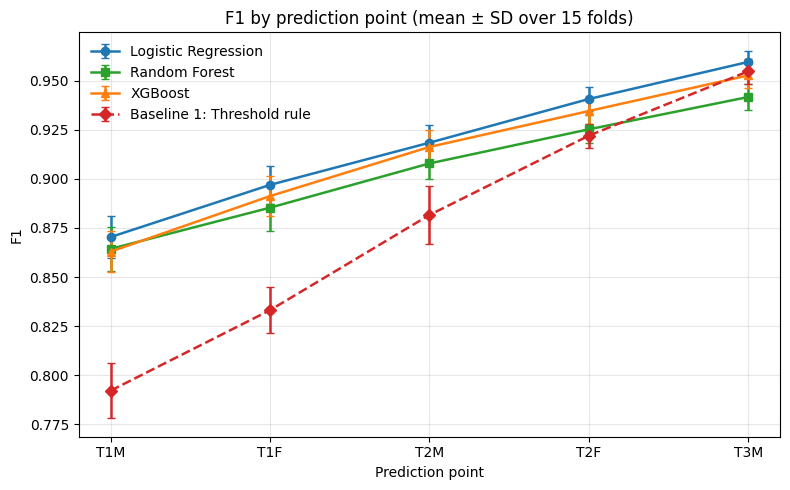

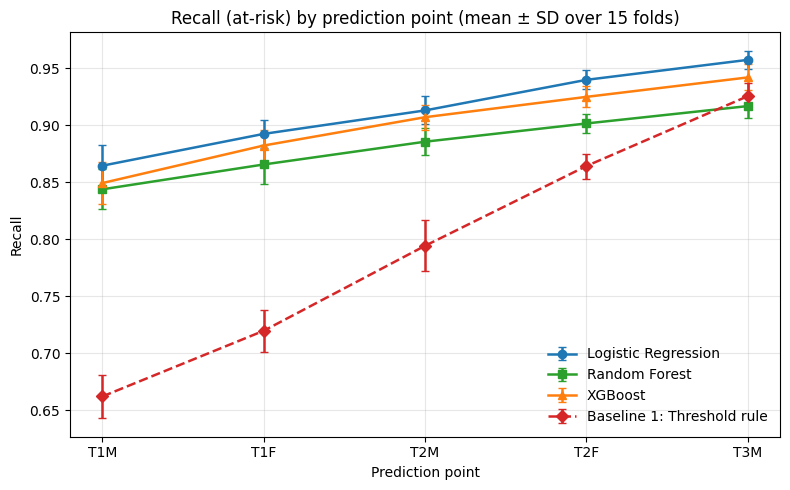

In [ ]:
colors = {LABELS["LR"]: "#1f77b4", LABELS["RF"]: "#2ca02c", LABELS["XGB"]: "#ff7f0e", B1_LABEL: "#d62728"}
markers = {LABELS["LR"]: "o", LABELS["RF"]: "s", LABELS["XGB"]: "^", B1_LABEL: "D"}
x = np.arange(len(POINTS))

def trend_plot(metric, fname, title):
    fig, ax = plt.subplots(figsize=(8, 5))
    for s in colors:
        sub = agg[agg.Strategy == s].set_index("Point").loc[POINTS]
        ax.errorbar(x, sub[f"{metric} mean"], yerr=sub[f"{metric} std"], label=s, color=colors[s],
                    marker=markers[s], capsize=3, linewidth=1.8,
                    linestyle="--" if s == B1_LABEL else "-")
    ax.set_xticks(x); ax.set_xticklabels(POINTS); ax.set_xlabel("Prediction point")
    ax.set_ylabel(metric); ax.set_title(title); ax.grid(alpha=.3); ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/{fname}", dpi=200); plt.show()

trend_plot("F1", "fig_f1_by_point.png", f"F1 by prediction point (mean ± SD over {CV_SPLITS * CV_REPEATS} folds)")
trend_plot("Recall", "fig_recall_by_point.png", f"Recall (at-risk) by prediction point (mean ± SD over {CV_SPLITS * CV_REPEATS} folds)")

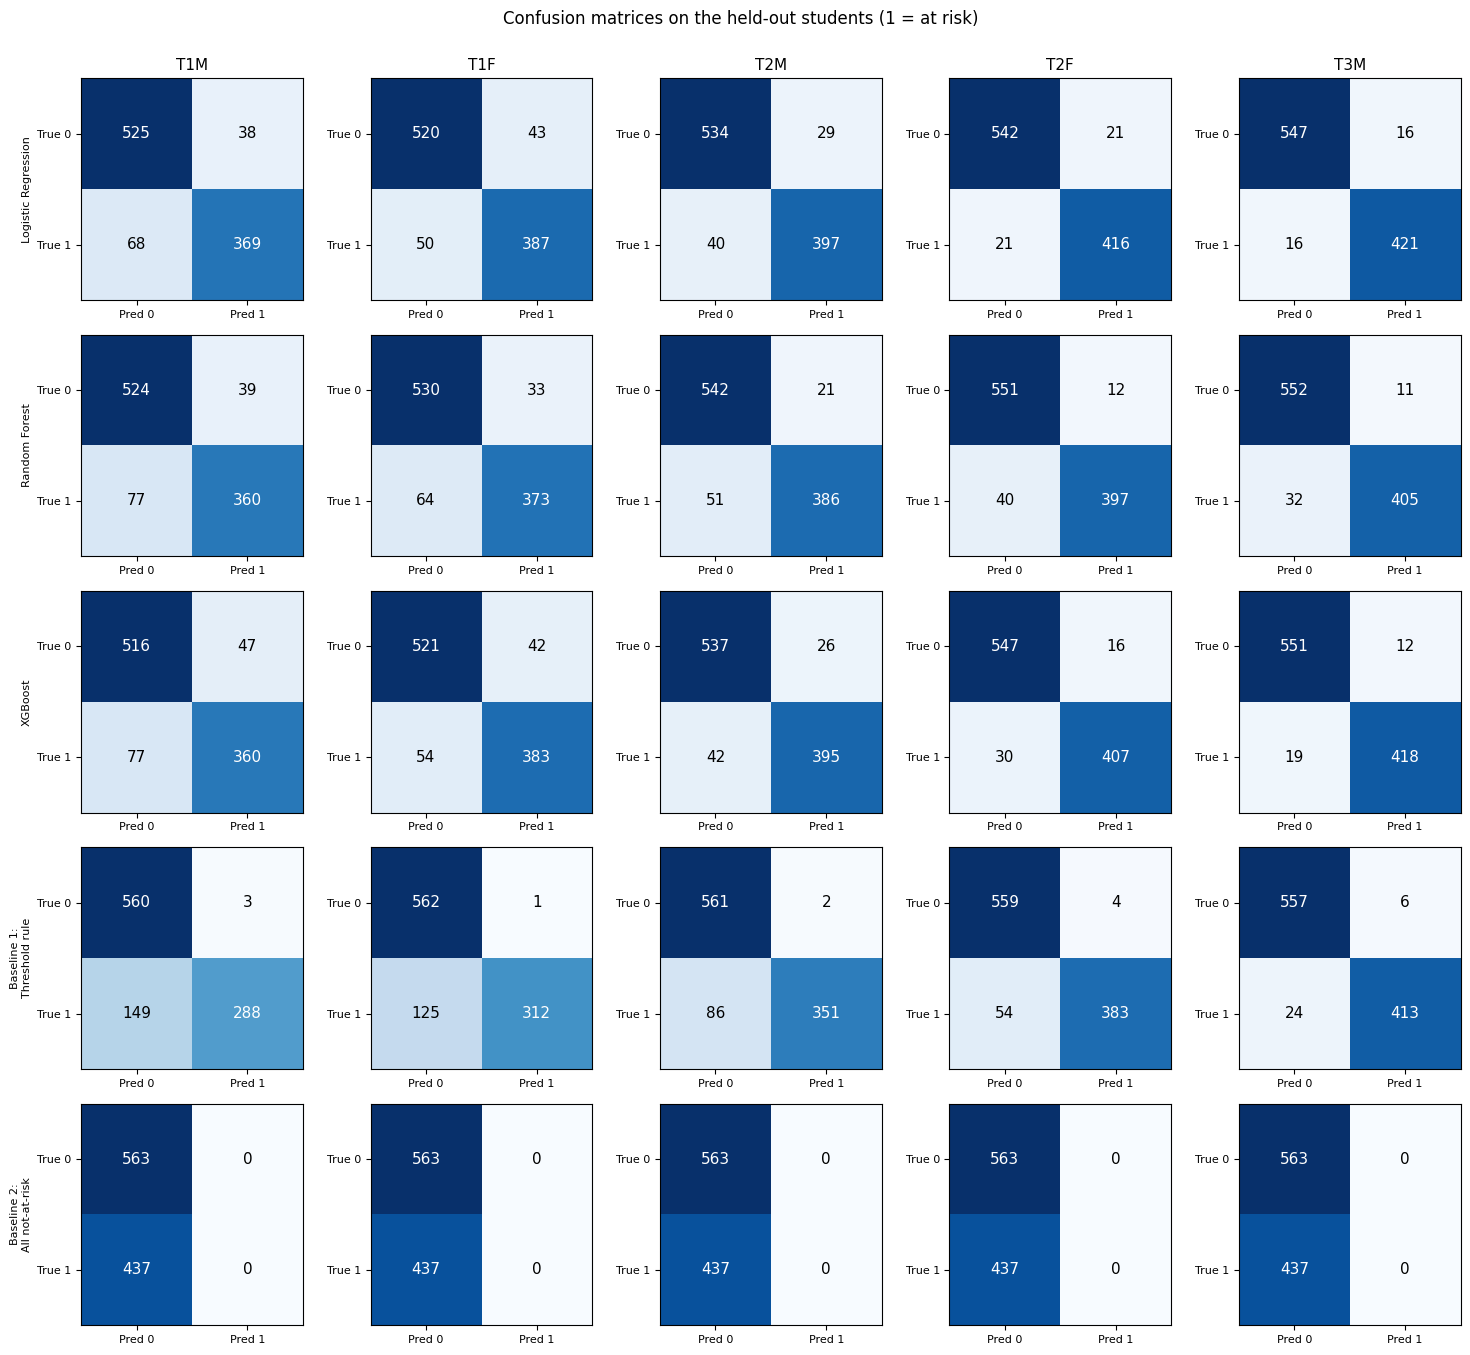

In [ ]:
# Confusion matrices: rows = strategies, columns = prediction points (held-out set)
fig, axes = plt.subplots(len(KEYS), len(POINTS), figsize=(3.0 * len(POINTS), 2.7 * len(KEYS)))
for i, key in enumerate(KEYS):
    for j, pt in enumerate(POINTS):
        row = holdout[(holdout.Point == pt) & (holdout.Strategy == LABELS[key])].iloc[0]
        m = np.array([[row.TN, row.FP], [row.FN, row.TP]])
        ax = axes[i, j]; ax.imshow(m, cmap="Blues", vmin=0, vmax=m.sum() / 2)
        for (r, c), v in np.ndenumerate(m):
            ax.text(c, r, int(v), ha="center", va="center", color="white" if v > m.sum() / 4 else "black", fontsize=11)
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Pred 0", "Pred 1"], fontsize=8); ax.set_yticklabels(["True 0", "True 1"], fontsize=8)
        if i == 0: ax.set_title(pt, fontsize=11)
        if j == 0: ax.set_ylabel(LABELS[key].replace(": ", ":\n"), fontsize=8)
fig.suptitle("Confusion matrices on the held-out students (1 = at risk)", y=1.0)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

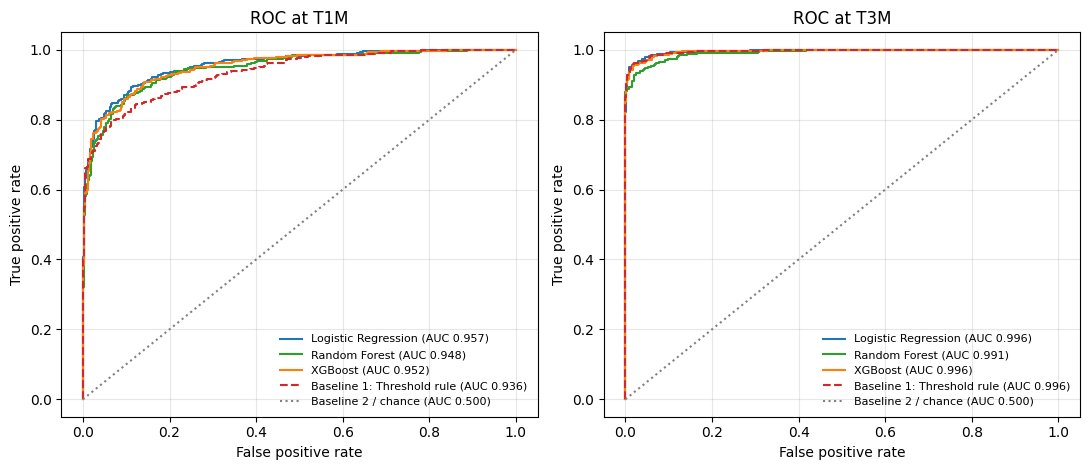

In [ ]:
# ROC curves at the earliest and latest prediction points (held-out set)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, pt in zip(axes, ["T1M", "T3M"]):
    for key in ["LR", "RF", "XGB", "B1"]:
        fpr, tpr, _ = roc_curve(Y_TEST[pt], holdout_preds[pt][key][1])
        auc = holdout[(holdout.Point == pt) & (holdout.Strategy == LABELS[key])]["ROC-AUC"].iloc[0]
        ax.plot(fpr, tpr, color=colors[LABELS[key]], linestyle="--" if key == "B1" else "-",
                label=f"{LABELS[key]} (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Baseline 2 / chance (AUC 0.500)")
    ax.set_title(f"ROC at {pt}"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.grid(alpha=.3); ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_roc_T1M_T3M.png", dpi=200); plt.show()

## 8. Summary for writing up 5.4.3

### 8.1 Reproducibility check

The modelling notebook reported these held-out values. Small differences can occur if your `xgboost`/`scikit-learn` versions differ from the original run; a large difference would indicate a different split or different data.

In [ ]:
expected = [("T1M", LABELS["LR"], "Accuracy", 0.894), ("T1M", LABELS["XGB"], "Accuracy", 0.876),
            ("T2F", LABELS["RF"], "F1", 0.9385), ("T3M", LABELS["LR"], "ROC-AUC", 0.9962),
            ("T3M", LABELS["XGB"], "Accuracy", 0.969)]
for pt, strat, metric, ref in expected:
    got = holdout[(holdout.Point == pt) & (holdout.Strategy == strat)][metric].iloc[0]
    flag = "OK " if abs(got - ref) <= 0.005 else "CHECK"
    print(f"[{flag}] {pt} {strat:22s} {metric:9s} notebook={ref:.4f}  here={got:.4f}")

[OK ] T1M Logistic Regression    Accuracy  notebook=0.8940  here=0.8940
[OK ] T1M XGBoost                Accuracy  notebook=0.8760  here=0.8760
[OK ] T2F Random Forest          F1        notebook=0.9385  here=0.9385
[OK ] T3M Logistic Regression    ROC-AUC   notebook=0.9962  here=0.9962
[OK ] T3M XGBoost                Accuracy  notebook=0.9690  here=0.9690


### 8.2 Findings computed from your results

These sentences are generated from the tables above. They are a starting point, so check each one against the tables and then reword it in your own words.

In [ ]:
print(f"Prevalence: {prevalence:.1%} at risk. Baseline 2 accuracy (majority class) = {1 - prevalence:.1%}; its recall, F1 and "
      f"ROC-AUC are 0, 0 and 0.5 at every point.\n")

first_not_sig = None
for pt in POINTS:
    ml = holdout[(holdout.Point == pt) & holdout.Strategy.isin(ML_LABELS)]
    best = ml.loc[ml.F1.idxmax()]
    b1 = holdout[(holdout.Point == pt) & (holdout.Strategy == B1_LABEL)].iloc[0]
    s = sig[(sig.Point == pt) & (sig.Strategy == best.Strategy)].iloc[0]
    verdict = ("significantly better than" if (s["Significant (Holm)"] and s.dF1 > 0)
               else "not significantly different from (Holm-adjusted)")
    if first_not_sig is None and not (s["Significant (Holm)"] and s.dF1 > 0): first_not_sig = pt
    print(f"{pt}: best model by F1 = {best.Strategy} (F1 {best.F1:.3f}, recall {best.Recall:.3f}); "
          f"Baseline 1 F1 {b1.F1:.3f}, recall {b1.Recall:.3f}. The difference in F1 is {s.dF1:+.3f} "
          f"(95% CI {s['dF1 CI low']:+.3f} to {s['dF1 CI high']:+.3f}); the model is {verdict} Baseline 1 "
          f"(McNemar p = {s['McNemar p']:.4f}, Holm p = {s['McNemar p (Holm)']:.4f}). "
          f"Baseline 1 missed {int(b1.FN)} of {int(b1.TP + b1.FN)} at-risk students; {best.Strategy} missed {int(best.FN)}.")
print()
if first_not_sig:
    print(f"From {first_not_sig} onward the best model's F1 advantage over Baseline 1 is no longer statistically reliable "
          f"after Holm adjustment (check the later points in the table above individually).")
else:
    print("The best model beat Baseline 1 significantly at every prediction point.")

Prevalence: 43.7% at risk. Baseline 2 accuracy (majority class) = 56.3%; its recall, F1 and ROC-AUC are 0, 0 and 0.5 at every point.

T1M: best model by F1 = Logistic Regression (F1 0.874, recall 0.844); Baseline 1 F1 0.791, recall 0.659. The difference in F1 is +0.083 (95% CI +0.056 to +0.113); the model is significantly better than Baseline 1 (McNemar p = 0.0000, Holm p = 0.0004). Baseline 1 missed 149 of 437 at-risk students; Logistic Regression missed 68.
T1F: best model by F1 = Logistic Regression (F1 0.893, recall 0.886); Baseline 1 F1 0.832, recall 0.714. The difference in F1 is +0.061 (95% CI +0.035 to +0.089); the model is significantly better than Baseline 1 (McNemar p = 0.0032, Holm p = 0.0414). Baseline 1 missed 125 of 437 at-risk students; Logistic Regression missed 50.
T2M: best model by F1 = XGBoost (F1 0.921, recall 0.904); Baseline 1 F1 0.889, recall 0.803. The difference in F1 is +0.032 (95% CI +0.013 to +0.053); the model is not significantly different from (Holm-adj

### 8.3 Compact tables to paste into the report

The first table gives held-out performance, the second gives variation across folds.

In [ ]:
t1 = headline[["Point", "Strategy", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].copy()
for c in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]: t1[c] = t1[c].map("{:.3f}".format)
print("TABLE A. Held-out test performance (at-risk = positive class)\n")
print(t1.to_markdown(index=False))
print("\n\nTABLE B. Cross-validated performance, mean ± SD over", CV_SPLITS * CV_REPEATS, "folds\n")
print(cv_display[["Point", "Strategy", "Recall", "F1", "ROC-AUC"]].to_markdown(index=False))

TABLE A. Held-out test performance (at-risk = positive class)

| Point   | Strategy                    |   Accuracy |   Precision |   Recall |    F1 |   ROC-AUC |
|:--------|:----------------------------|-----------:|------------:|---------:|------:|----------:|
| T1M     | Logistic Regression         |      0.894 |       0.907 |    0.844 | 0.874 |     0.957 |
| T1M     | Random Forest               |      0.884 |       0.902 |    0.824 | 0.861 |     0.948 |
| T1M     | XGBoost                     |      0.876 |       0.885 |    0.824 | 0.853 |     0.952 |
| T1M     | Baseline 1: Threshold rule  |      0.848 |       0.99  |    0.659 | 0.791 |     0.936 |
| T1M     | Baseline 2: All not-at-risk |      0.563 |       0     |    0     | 0     |     0.5   |
| T1F     | Logistic Regression         |      0.907 |       0.9   |    0.886 | 0.893 |     0.972 |
| T1F     | Random Forest               |      0.903 |       0.919 |    0.854 | 0.885 |     0.967 |
| T1F     | XGBoost                  

### 8.4 Package everything for download

In [ ]:
import shutil
archive = shutil.make_archive("ch5_4_3_outputs", "zip", OUT_DIR)
print("Saved:", sorted(os.listdir(OUT_DIR)))
print("Archive:", archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

Saved: ['fig_confusion_matrices.png', 'fig_f1_by_point.png', 'fig_recall_by_point.png', 'fig_roc_T1M_T3M.png', 'table_cv_display.csv', 'table_cv_mean_sd.csv', 'table_cv_raw_per_fold.csv', 'table_dataset_summary.csv', 'table_error_analysis.csv', 'table_error_distance_to_pass_mark.csv', 'table_holdout_classwise.csv', 'table_holdout_confusion.csv', 'table_holdout_full.csv', 'table_holdout_headline.csv', 'table_model_vs_model.csv', 'table_significance_vs_baseline1.csv']
Archive: /content/ch5_4_3_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes on interpreting these results

* **Synthetic data.** The students come from a generator, not a real school. The results show how the strategies behave under the generator's assumptions. They are not evidence of real-world accuracy, and the report should say so.
* **Recall over accuracy.** The outcome is close to balanced (about 44% at risk), so accuracy alone is weak evidence. Lead with recall and F1 for the at-risk class.
* **Baseline 1's AUC** is computed from its underlying average score (100 − mean) so that it can be placed on a ROC curve. The rule itself only outputs a yes/no decision, so recall and F1 are the fairer comparison.
* **Multiple comparisons.** Quote the Holm-adjusted p-values when claiming a model beats Baseline 1.
* **Decision support, not a verdict.** A flag is a signal for the educator to review, not a determination that a student will fail.

In [ ]:
import pandas as pd

OUT = "ch5_4_3_outputs"
cv  = pd.read_csv(f"{OUT}/table_cv_mean_sd.csv")
ho  = pd.read_csv(f"{OUT}/table_holdout_full.csv")
sig = pd.read_csv(f"{OUT}/table_significance_vs_baseline1.csv")

POINTS = ["T1M", "T1F", "T2M", "T2F", "T3M"]
ORDER  = ["Logistic Regression", "Random Forest", "XGBoost",
          "Baseline 1: Threshold rule", "Baseline 2: All not-at-risk"]
CV_METRICS = ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]

rows = []
for pt in POINTS:
    for s in ORDER:
        c = cv[(cv.Point == pt) & (cv.Strategy == s)].iloc[0]
        h = ho[(ho.Point == pt) & (ho.Strategy == s)].iloc[0]
        row = {"Point": pt, "Strategy": s}
        for m in CV_METRICS:
            row[m] = f"{c[f'{m} mean']:.3f} ± {c[f'{m} std']:.3f}"
        row["Recall (held-out)"] = f"{h['Recall']:.3f}"
        row["F1 (held-out)"] = f"{h['F1']:.3f}"
        row["Missed (FN)"] = int(h["FN"])
        row["False alarms (FP)"] = int(h["FP"])
        if s in ORDER[:3]:
            g = sig[(sig.Point == pt) & (sig.Strategy == s)].iloc[0]
            star = "*" if g["Significant (Holm)"] and g["dF1"] > 0 else ""
            p = g["McNemar p (Holm)"]
            row["vs Baseline 1: Holm p"] = ("<0.001" if p < 0.001 else f"{p:.3f}") + star
        else:
            row["vs Baseline 1: Holm p"] = "–"
        rows.append(row)

master = pd.DataFrame(rows)
master.to_csv(f"{OUT}/table_master_findings.csv", index=False)
print(master.to_markdown(index=False))

| Point   | Strategy                    | Accuracy      | Balanced Accuracy   | Precision     | Recall        | F1            | ROC-AUC       | PR-AUC        |   Recall (held-out) |   F1 (held-out) |   Missed (FN) |   False alarms (FP) | vs Baseline 1: Holm p   |
|:--------|:----------------------------|:--------------|:--------------------|:--------------|:--------------|:--------------|:--------------|:--------------|--------------------:|----------------:|--------------:|--------------------:|:------------------------|
| T1M     | Logistic Regression         | 0.887 ± 0.009 | 0.885 ± 0.010       | 0.877 ± 0.013 | 0.864 ± 0.018 | 0.870 ± 0.011 | 0.958 ± 0.004 | 0.954 ± 0.005 |               0.844 |           0.874 |            68 |                  38 | <0.001*                 |
| T1M     | Random Forest               | 0.884 ± 0.009 | 0.880 ± 0.010       | 0.886 ± 0.012 | 0.844 ± 0.017 | 0.864 ± 0.011 | 0.953 ± 0.006 | 0.948 ± 0.007 |               0.824 |           0.861 |         